In [ ]:

%pip install -q mne scikit-learn pandas numpy scipy matplotlib seaborn streamlit


In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import mne

print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("scikit-learn:", sklearn.__version__)
print("MNE:", mne.__version__)
print("NeuroSignal AI environment ready!")


NumPy: 2.1.3
Pandas: 2.2.3
scikit-learn: 1.6.1
MNE: 1.13.2
NeuroSignal AI environment ready!


In [ ]:

import requests

url = "https://physionet.org/files/eegmmidb/1.0.0/S001/S001R07.edf"
filename = "S001R07.edf"

response = requests.get(url, timeout=60)
response.raise_for_status()

with open(filename, "wb") as f:
    f.write(response.content)

print("Download successful!")
print("File size:", round(len(response.content) / 1024, 2), "KB")


Download successful!
File size: 2536.03 KB


In [ ]:

import mne

raw = mne.io.read_raw_edf(
    "S001R07.edf",
    preload=True,
    verbose=False
)

print("EEG loaded successfully!")
print("Channels:", len(raw.ch_names))
print("Sampling rate:", raw.info["sfreq"], "Hz")
print("Duration:", round(raw.times[-1], 2), "seconds")

print("Annotations:")
print(raw.annotations)


EEG loaded successfully!
Channels: 64
Sampling rate: 160.0 Hz
Duration: 124.99 seconds
Annotations:
<Annotations | 30 segments: T0 (15), T1 (8), T2 (7)>


In [ ]:

# Display the annotation descriptions and their timings

print("Annotation descriptions:")
print(set(raw.annotations.description))

print("\nFirst 15 annotations:")
for onset, duration, description in zip(
    raw.annotations.onset,
    raw.annotations.duration,
    raw.annotations.description
):
    print(
        f"Time: {onset:7.2f}s | "
        f"Duration: {duration:5.2f}s | "
        f"Event: {description}"
    )


Annotation descriptions:
{'T1', 'T0', 'T2'}

First 15 annotations:
Time:    0.00s | Duration:  4.20s | Event: T0
Time:    4.20s | Duration:  4.10s | Event: T1
Time:    8.30s | Duration:  4.20s | Event: T0
Time:   12.50s | Duration:  4.10s | Event: T2
Time:   16.60s | Duration:  4.20s | Event: T0
Time:   20.80s | Duration:  4.10s | Event: T1
Time:   24.90s | Duration:  4.20s | Event: T0
Time:   29.10s | Duration:  4.10s | Event: T2
Time:   33.20s | Duration:  4.20s | Event: T0
Time:   37.40s | Duration:  4.10s | Event: T1
Time:   41.50s | Duration:  4.20s | Event: T0
Time:   45.70s | Duration:  4.10s | Event: T2
Time:   49.80s | Duration:  4.20s | Event: T0
Time:   54.00s | Duration:  4.10s | Event: T2
Time:   58.10s | Duration:  4.20s | Event: T0
Time:   62.30s | Duration:  4.10s | Event: T1
Time:   66.40s | Duration:  4.20s | Event: T0
Time:   70.60s | Duration:  4.10s | Event: T1
Time:   74.70s | Duration:  4.20s | Event: T0
Time:   78.90s | Duration:  4.10s | Event: T2
Time:   83.00

Using matplotlib as 2D backend.
For automatic theme detection, "darkdetect" has to be installed! You can install it with `pip install darkdetect`


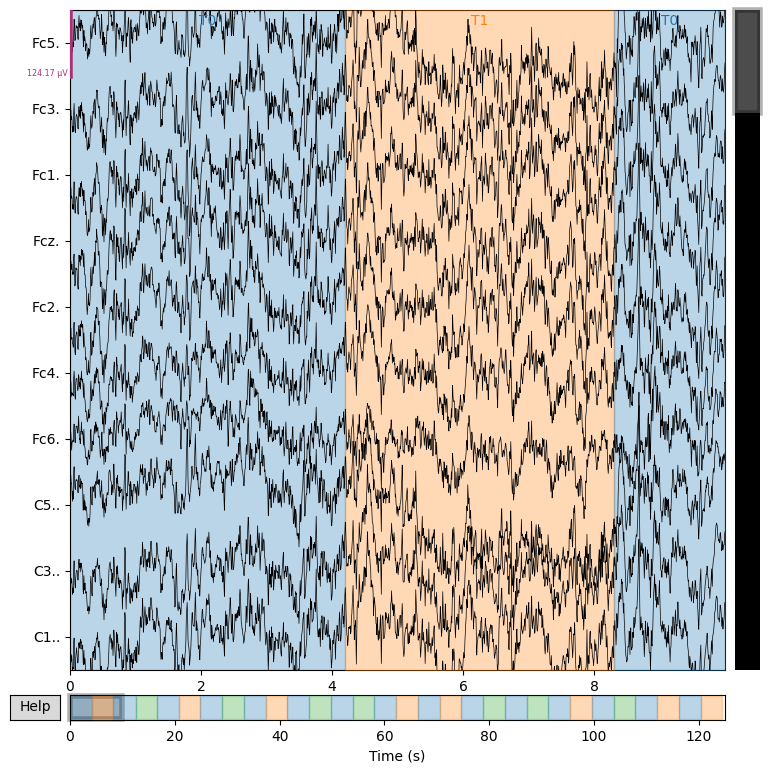

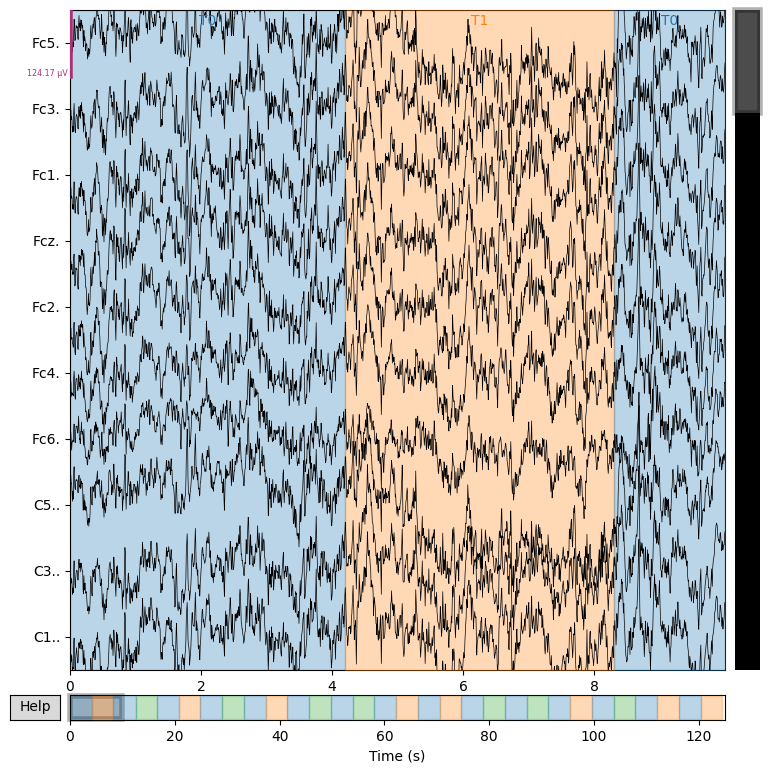

In [ ]:

# Plot the first 10 seconds of EEG
raw.plot(
    duration=10,
    n_channels=10,
    scalings="auto"
)


In [ ]:

import numpy as np
import mne

# Convert annotations into events
events, event_id = mne.events_from_annotations(raw, verbose=False)

print("Event mapping:", event_id)

# Keep only left-fist (T1) and right-fist (T2) trials
selected_events = events[
    np.isin(events[:, 2], [event_id["T1"], event_id["T2"]])
]

# Extract epochs: 0.5 to 3.5 seconds after each event
epochs = mne.Epochs(
    raw,
    selected_events,
    event_id={"left_fist": event_id["T1"],
              "right_fist": event_id["T2"]},
    tmin=0.5,
    tmax=3.5,
    baseline=None,
    preload=True,
    picks="eeg",
    verbose=False
)

# Obtain EEG data: trials x channels x time points
X_eeg = epochs.get_data()

# Labels: 0 = left fist, 1 = right fist
y = epochs.events[:, 2]
y = (y == event_id["T2"]).astype(int)

print("\nEEG trials shape:", X_eeg.shape)
print("Labels shape:", y.shape)
print("Number of left-fist trials:", np.sum(y == 0))
print("Number of right-fist trials:", np.sum(y == 1))
print("Epoch duration:", epochs.times[-1], "seconds")


Event mapping: {'T0': 1, 'T1': 2, 'T2': 3}

EEG trials shape: (15, 64, 481)
Labels shape: (15,)
Number of left-fist trials: 8
Number of right-fist trials: 7
Epoch duration: 3.5 seconds


In [ ]:

import numpy as np
import pandas as pd
from scipy.signal import welch

# Frequency bands in Hz
bands = {
    "theta": (4, 8),
    "alpha": (8, 13),
    "beta": (13, 30),
    "low_gamma": (30, 40)
}

sfreq = raw.info["sfreq"]
feature_rows = []

# Process every trial and every EEG channel
for trial in X_eeg:
    trial_features = []

    for channel_signal in trial:
        freqs, psd = welch(
            channel_signal,
            fs=sfreq,
            nperseg=256
        )

        for band_name, (low, high) in bands.items():
            mask = (freqs >= low) & (freqs < high)

            # Average power within the frequency band
            power = np.mean(psd[mask])
            trial_features.append(np.log10(power + 1e-12))

    feature_rows.append(trial_features)

# Convert features to a 2D ML matrix
X_features = np.asarray(feature_rows)

print("Feature matrix shape:", X_features.shape)
print("Labels shape:", y.shape)
print("Number of features per trial:", X_features.shape[1])
print("All features finite:", np.isfinite(X_features).all())


Feature matrix shape: (15, 256)
Labels shape: (15,)
Number of features per trial: 256
All features finite: True


In [ ]:

import numpy as np

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# Define cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Baseline model
dummy_model = DummyClassifier(strategy="most_frequent")

# ML model with scaling
logistic_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=2000, random_state=42)
)

# Evaluate both models
scoring = {
    "accuracy": "accuracy",
    "balanced_accuracy": "balanced_accuracy",
    "f1": "f1"
}

for name, model in [
    ("Dummy baseline", dummy_model),
    ("Logistic Regression", logistic_model)
]:
    results = cross_validate(
        model,
        X_features,
        y,
        cv=cv,
        scoring=scoring
    )

    print(f"\n{name}")
    for metric in scoring:
        scores = results[f"test_{metric}"]
        print(
            f"{metric}: {scores.mean():.3f} "
            f"+/- {scores.std():.3f}"
        )



Dummy baseline
accuracy: 0.533 +/- 0.163
balanced_accuracy: 0.500 +/- 0.000
f1: 0.000 +/- 0.000

Logistic Regression
accuracy: 0.400 +/- 0.327
balanced_accuracy: 0.350 +/- 0.339
f1: 0.200 +/- 0.400


In [ ]:

from mne.decoding import CSP
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_validate
import numpy as np

# Filter a copy of the recording to the 8–30 Hz band
raw_filtered = raw.copy().filter(
    l_freq=8,
    h_freq=30,
    verbose=False
)

# Recreate epochs from the same selected events
epochs_filtered = mne.Epochs(
    raw_filtered,
    selected_events,
    event_id={
        "left_fist": event_id["T1"],
        "right_fist": event_id["T2"]
    },
    tmin=0.5,
    tmax=3.5,
    baseline=None,
    preload=True,
    picks="eeg",
    verbose=False
)

X_csp = epochs_filtered.get_data()

# Reuse the verified binary labels
y_csp = y.copy()

# CSP learns spatial features from EEG channels
csp_model = Pipeline([
    ("csp", CSP(
        n_components=4,
        reg="ledoit_wolf",
        log=True
    )),
    ("classifier", LogisticRegression(
        max_iter=2000,
        class_weight="balanced"
    ))
])

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

results = cross_validate(
    csp_model,
    X_csp,
    y_csp,
    cv=cv,
    scoring={
        "accuracy": "accuracy",
        "balanced_accuracy": "balanced_accuracy",
        "f1": "f1"
    }
)

print("CSP + Logistic Regression")
for metric in ["accuracy", "balanced_accuracy", "f1"]:
    scores = results[f"test_{metric}"]
    print(f"{metric}: {scores.mean():.3f} +/- {scores.std():.3f}")


Computing rank from data with rank=None
    Using tolerance 0.00013 (2.2e-16 eps * 64 dim * 9.4e+09  max singular value)
    Estimated rank (data): 64
    data: rank 64 computed from 64 data channels with 0 projectors
Reducing data rank from 64 -> 64
Estimating class=0 covariance using LEDOIT_WOLF
Done.
Estimating class=1 covariance using LEDOIT_WOLF
Done.
Computing rank from data with rank=None
    Using tolerance 0.00014 (2.2e-16 eps * 64 dim * 9.7e+09  max singular value)
    Estimated rank (data): 64
    data: rank 64 computed from 64 data channels with 0 projectors
Reducing data rank from 64 -> 64
Estimating class=0 covariance using LEDOIT_WOLF
Done.
Estimating class=1 covariance using LEDOIT_WOLF
Done.
Computing rank from data with rank=None
    Using tolerance 0.00013 (2.2e-16 eps * 64 dim * 9.4e+09  max singular value)
    Estimated rank (data): 64
    data: rank 64 computed from 64 data channels with 0 projectors
Reducing data rank from 64 -> 64
Estimating class=0 covariance u

In [ ]:

import requests
import numpy as np
import mne
from pathlib import Path

X_all = []
y_all = []
groups = []

data_dir = Path("eeg_data")
data_dir.mkdir(exist_ok=True)

for subject in range(1, 11):
    subject_id = f"S{subject:03d}"
    filename = f"{subject_id}R04.edf"
    filepath = data_dir / filename

    url = (
        "https://physionet.org/files/eegmmidb/1.0.0/"
        f"{subject_id}/{filename}"
    )

    # Download the recording if it is not already present
    if not filepath.exists():
        response = requests.get(url, timeout=90)
        response.raise_for_status()
        filepath.write_bytes(response.content)

    raw_subject = mne.io.read_raw_edf(
        str(filepath), preload=True, verbose=False
    )

    # Band-pass filter for motor-imagery EEG
    raw_subject.filter(
        l_freq=8, h_freq=30, verbose=False
    )

    events, event_id = mne.events_from_annotations(
        raw_subject, verbose=False
    )

    # Select only the two motor-imagery classes
    selected = events[
        np.isin(
            events[:, 2],
            [event_id["T1"], event_id["T2"]]
        )
    ]

    epochs_subject = mne.Epochs(
        raw_subject,
        selected,
        event_id={
            "left_fist": event_id["T1"],
            "right_fist": event_id["T2"]
        },
        tmin=0.5,
        tmax=3.5,
        baseline=None,
        preload=True,
        picks="eeg",
        verbose=False
    )

    X_subject = epochs_subject.get_data()
    y_subject = (
        epochs_subject.events[:, 2] == event_id["T2"]
    ).astype(int)

    X_all.extend(X_subject)
    y_all.extend(y_subject)
    groups.extend([subject] * len(y_subject))

    print(
        subject_id,
        "| trials:", len(y_subject),
        "| left:", np.sum(y_subject == 0),
        "| right:", np.sum(y_subject == 1)
    )

X_all = np.asarray(X_all)
y_all = np.asarray(y_all)
groups = np.asarray(groups)

print("\nCombined EEG shape:", X_all.shape)
print("Combined labels:", y_all.shape)
print("Unique participants:", len(np.unique(groups)))


S001 | trials: 15 | left: 8 | right: 7
S002 | trials: 15 | left: 7 | right: 8
S003 | trials: 15 | left: 8 | right: 7
S004 | trials: 15 | left: 8 | right: 7
S005 | trials: 15 | left: 7 | right: 8
S006 | trials: 15 | left: 8 | right: 7
S007 | trials: 15 | left: 8 | right: 7
S008 | trials: 15 | left: 7 | right: 8
S009 | trials: 15 | left: 8 | right: 7
S010 | trials: 15 | left: 8 | right: 7

Combined EEG shape: (150, 64, 481)
Combined labels: (150,)
Unique participants: 10


In [ ]:

from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import GroupKFold, cross_validate
from mne.decoding import CSP

# EEG-specific machine learning pipeline
model = Pipeline([
    ("csp", CSP(
        n_components=4,
        reg="ledoit_wolf",
        log=True
    )),
    ("classifier", LogisticRegression(
        max_iter=2000,
        class_weight="balanced"
    ))
])

# Keep every participant entirely within one fold
cv = GroupKFold(n_splits=5)

scoring = {
    "accuracy": "accuracy",
    "balanced_accuracy": "balanced_accuracy",
    "f1": "f1"
}

# Evaluate the CSP model
results = cross_validate(
    model,
    X_all,
    y_all,
    groups=groups,
    cv=cv,
    scoring=scoring,
    n_jobs=1
)

print("CSP + Logistic Regression")
for metric in scoring:
    scores = results[f"test_{metric}"]
    print(
        f"{metric}: {scores.mean():.3f} "
        f"+/- {scores.std():.3f}"
    )

# Compare against a majority-class baseline
baseline = DummyClassifier(strategy="most_frequent")

baseline_results = cross_validate(
    baseline,
    X_all,
    y_all,
    groups=groups,
    cv=cv,
    scoring=scoring,
    n_jobs=1
)

print("\nMajority-class baseline")
for metric in scoring:
    scores = baseline_results[f"test_{metric}"]
    print(
        f"{metric}: {scores.mean():.3f} "
        f"+/- {scores.std():.3f}"
    )


Computing rank from data with rank=None
    Using tolerance 0.00035 (2.2e-16 eps * 64 dim * 2.5e+10  max singular value)
    Estimated rank (data): 64
    data: rank 64 computed from 64 data channels with 0 projectors
Reducing data rank from 64 -> 64
Estimating class=0 covariance using LEDOIT_WOLF
Done.
Estimating class=1 covariance using LEDOIT_WOLF
Done.
Computing rank from data with rank=None
    Using tolerance 0.00034 (2.2e-16 eps * 64 dim * 2.4e+10  max singular value)
    Estimated rank (data): 64
    data: rank 64 computed from 64 data channels with 0 projectors
Reducing data rank from 64 -> 64
Estimating class=0 covariance using LEDOIT_WOLF
Done.
Estimating class=1 covariance using LEDOIT_WOLF
Done.
Computing rank from data with rank=None
    Using tolerance 0.00032 (2.2e-16 eps * 64 dim * 2.2e+10  max singular value)
    Estimated rank (data): 64
    data: rank 64 computed from 64 data channels with 0 projectors
Reducing data rank from 64 -> 64
Estimating class=0 covariance u

,Model,Metric,Mean score,Standard deviation
0,CSP + Logistic Regression,accuracy,0.507,0.025
1,CSP + Logistic Regression,balanced_accuracy,0.506,0.025
2,CSP + Logistic Regression,f1,0.345,0.208
3,Majority-class baseline,accuracy,0.513,0.016
4,Majority-class baseline,balanced_accuracy,0.500,0.000
5,Majority-class baseline,f1,0.000,0.000


Saved: neurosignal_results.csv


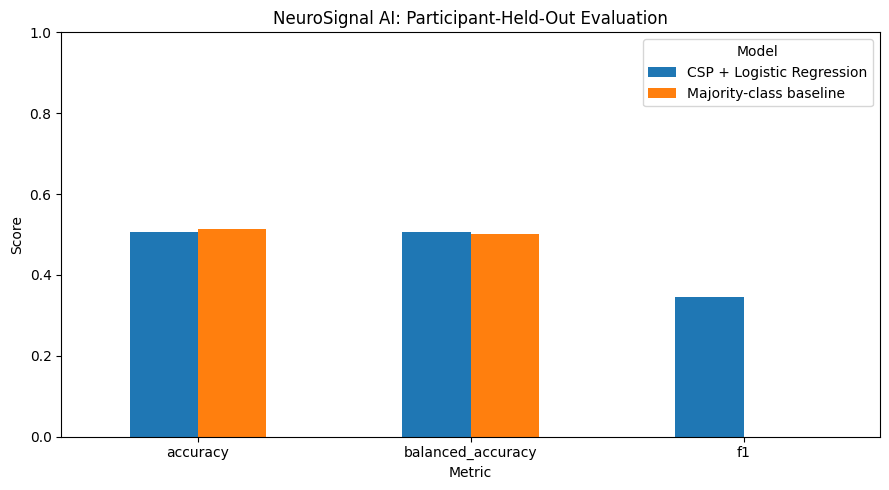

Saved: neurosignal_results.png


In [ ]:

import pandas as pd
import matplotlib.pyplot as plt

# Build a results table from the cross-validation outputs
rows = []

for model_name, result in [
    ("CSP + Logistic Regression", results),
    ("Majority-class baseline", baseline_results)
]:
    for metric in ["accuracy", "balanced_accuracy", "f1"]:
        scores = result[f"test_{metric}"]

        rows.append({
            "Model": model_name,
            "Metric": metric,
            "Mean score": scores.mean(),
            "Standard deviation": scores.std()
        })

results_df = pd.DataFrame(rows)

display(results_df.round(3))

# Save the experiment results
results_df.to_csv("neurosignal_results.csv", index=False)

print("Saved: neurosignal_results.csv")

# Visualize the mean scores
pivot = results_df.pivot(
    index="Metric",
    columns="Model",
    values="Mean score"
)

pivot.plot(kind="bar", ylim=(0, 1), figsize=(9, 5))
plt.title("NeuroSignal AI: Participant-Held-Out Evaluation")
plt.ylabel("Score")
plt.xlabel("Metric")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("neurosignal_results.png", dpi=150)
plt.show()

print("Saved: neurosignal_results.png")


In [ ]:

%pip -q install streamlit


In [ ]:

%%writefile app.py
import streamlit as st
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

st.set_page_config(
    page_title="NeuroSignal AI",
    page_icon="🧠",
    layout="wide"
)

st.title("🧠 NeuroSignal AI")
st.subheader("EEG Classification & Research Analytics")

st.write(
    "An experimental EEG machine-learning project "
    "evaluating motor-imagery classification and "
    "generalization to unseen participants."
)

results_path = Path("neurosignal_results.csv")

if not results_path.exists():
    st.error(
        "Results file not found. Run the evaluation "
        "and CSV export cells in your Colab notebook first."
    )
    st.stop()

df = pd.read_csv(results_path)

# Select the results for the participant-held-out experiment
accuracy_row = df[
    (df["Model"] == "CSP + Logistic Regression") &
    (df["Metric"] == "accuracy")
]

balanced_row = df[
    (df["Model"] == "CSP + Logistic Regression") &
    (df["Metric"] == "balanced_accuracy")
]

f1_row = df[
    (df["Model"] == "CSP + Logistic Regression") &
    (df["Metric"] == "f1")
]

if accuracy_row.empty or balanced_row.empty or f1_row.empty:
    st.error("Expected evaluation metrics are missing from the CSV.")
    st.stop()

accuracy = accuracy_row["Mean score"].iloc[0]
balanced_accuracy = balanced_row["Mean score"].iloc[0]
f1 = f1_row["Mean score"].iloc[0]

st.markdown("### Model Performance")

c1, c2, c3 = st.columns(3)

c1.metric("Accuracy", f"{accuracy:.1%}")
c2.metric("Balanced Accuracy", f"{balanced_accuracy:.1%}")
c3.metric("F1 Score", f"{f1:.1%}")

st.caption(
    "These are preliminary participant-held-out results "
    "from 10 participants. They are not clinical performance "
    "estimates or evidence of a validated EEG classifier."
)

st.markdown("### Model Comparison")

pivot = df.pivot(
    index="Metric",
    columns="Model",
    values="Mean score"
)

st.bar_chart(pivot)

st.markdown("### Detailed Results")
st.dataframe(df.round(3), use_container_width=True)

st.markdown("### About this project")
st.write(
    "NeuroSignal AI uses MNE-Python for EEG processing, "
    "Common Spatial Patterns for feature extraction, and "
    "scikit-learn for classification and evaluation."
)

st.info(
    "Research limitation: performance on unseen participants "
    "is close to the majority-class baseline in this experiment. "
    "Further validation and model improvement are required."
)


Overwriting app.py


In [ ]:

!streamlit run app.py --server.port 8501 \
    --server.headless true \
    > streamlit.log 2>&1 &


In [ ]:

!cat streamlit.log


In [ ]:

import os

for filename in [
    "app.py",
    "neurosignal_results.csv",
    "neurosignal_results.png",
    "requirements.txt",
    "README.md"
]:
    print(
        f"{filename}:",
        "FOUND" if os.path.exists(filename) else "MISSING"
    )


app.py: FOUND
neurosignal_results.csv: FOUND
neurosignal_results.png: FOUND
requirements.txt: MISSING
README.md: MISSING


In [ ]:

from pathlib import Path

Path("README.md").write_text("""# NeuroSignal AI

**EEG Classification and Research Analytics**

NeuroSignal AI is an experimental machine-learning project
that investigates EEG motor-imagery classification and
generalization to unseen participants.

## Features
- EEG preprocessing with MNE-Python
- Frequency-band power features
- Common Spatial Patterns (CSP)
- Logistic Regression classification
- Participant-held-out evaluation
- Interactive Streamlit dashboard

## Technology
Python, MNE-Python, NumPy, Pandas, SciPy,
scikit-learn, Matplotlib and Streamlit.

## Dataset
PhysioNet EEG Motor Movement/Imagery Dataset:
https://physionet.org/content/eegmmidb/

## Preliminary results
The experiment used recordings from 10 participants.

- CSP + Logistic Regression accuracy: 50.7%
- Balanced accuracy: 50.6%
- F1 score: 34.5%
- Majority-class baseline accuracy: 51.3%

These results do not demonstrate useful generalization
beyond the baseline. Further evaluation is required.

## Run locally
Install dependencies:

    pip install -r requirements.txt

Start the dashboard:

    streamlit run app.py

Keep neurosignal_results.csv in the project directory.

## Limitations
This is a small experimental study, not a validated
EEG classifier or a medical diagnostic system.

## Future work
- Evaluate more participants and recording sessions
- Investigate signal preprocessing and feature selection
- Improve model evaluation and reproducibility

## Author
[Your Name]

For educational and research purposes only.
""")

Path("requirements.txt").write_text(
    "mne\nnumpy\npandas\nscipy\nscikit-learn\nmatplotlib\nstreamlit\n"
)

Path(".gitignore").write_text(
    "__pycache__/\n*.py[cod]\n.ipynb_checkpoints/\n"
    ".venv/\neeg_data/\n*.edf\n.DS_Store\n"
)

print("README.md created:", Path("README.md").exists())
print("requirements.txt created:", Path("requirements.txt").exists())
print(".gitignore created:", Path(".gitignore").exists())


README.md created: True
requirements.txt created: True
.gitignore created: True


In [ ]:

from pathlib import Path

required_files = [
    "app.py",
    "neurosignal_results.csv",
    "neurosignal_results.png",
    "requirements.txt",
    "README.md",
    ".gitignore"
]

for name in required_files:
    path = Path(name)
    print(f"{name}: {'FOUND' if path.exists() else 'MISSING'}")

if Path("neurosignal_results.csv").exists():
    import pandas as pd
    print("\nSaved evaluation results:")
    print(pd.read_csv("neurosignal_results.csv").round(3))


app.py: FOUND
neurosignal_results.csv: FOUND
neurosignal_results.png: FOUND
requirements.txt: FOUND
README.md: FOUND
.gitignore: FOUND

Saved evaluation results:
                       Model             Metric  Mean score  \
0  CSP + Logistic Regression           accuracy       0.507   
1  CSP + Logistic Regression  balanced_accuracy       0.506   
2  CSP + Logistic Regression                 f1       0.345   
3    Majority-class baseline           accuracy       0.513   
4    Majority-class baseline  balanced_accuracy       0.500   
5    Majority-class baseline                 f1       0.000   

   Standard deviation  
0               0.025  
1               0.025  
2               0.208  
3               0.016  
4               0.000  
5               0.000  


In [ ]:

import requests
import subprocess

# Check whether the Streamlit server responds locally
try:
    response = requests.get(
        "http://127.0.0.1:8502/_stcore/health",
        timeout=5
    )
    print("Server status:", response.status_code)
    print("Response:", response.text)
except Exception as e:
    print("Server is not responding:", repr(e))

# Inspect the latest Streamlit log
print("\n--- Streamlit log ---")
subprocess.run(["bash", "-lc", "tail -40 streamlit.log"])


Server status: 200
Response: ok

--- Streamlit log ---


CompletedProcess(args=['bash', '-lc', 'tail -40 streamlit.log'], returncode=0)

In [ ]:

!pkill -f "streamlit run app.py" || true


^C


In [ ]:

!streamlit run app.py \
    --server.port 8502 \
    --server.address 0.0.0.0 \
    --server.headless true \
    --server.enableCORS false \
    --server.enableXsrfProtection false \
    > streamlit.log 2>&1 &


In [ ]:

from google.colab import output
import time
import requests

# Confirm the dashboard is responding locally
for attempt in range(10):
    try:
        r = requests.get(
            "http://127.0.0.1:8502/_stcore/health",
            timeout=3
        )
        if r.status_code == 200:
            print("Streamlit is healthy!")
            break
    except requests.RequestException:
        time.sleep(2)
else:
    raise RuntimeError("Streamlit did not start. Check streamlit.log.")

# Generate the browser-accessible Colab proxy URL
url = output.eval_js(
    "google.colab.kernel.proxyPort(8502)"
)

print("\nNeuroSignal AI dashboard:")
print(url)


Streamlit is healthy!

NeuroSignal AI dashboard:
https://8502-m-s-kkb-usw1c1-9alvu1enkfji-c.us-west1-1.prod.colab.dev


In [ ]:

!tail -30 streamlit.log




2026-10-12 18:50:35.787 Uvicorn server started on 0.0.0.0:8502

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8502
  Network URL: http://172.28.0.12:8502
  External URL: http://136.67.138.249:8502



In [ ]:
with open("app.py", "r", encoding="utf-8") as f:
    print(f.read())

import streamlit as st
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

st.set_page_config(
    page_title="NeuroSignal AI",
    page_icon="🧠",
    layout="wide"
)

st.title("🧠 NeuroSignal AI")
st.subheader("EEG Classification & Research Analytics")

st.write(
    "An experimental EEG machine-learning project "
    "evaluating motor-imagery classification and "
    "generalization to unseen participants."
)

results_path = Path("neurosignal_results.csv")

if not results_path.exists():
    st.error(
        "Results file not found. Run the evaluation "
        "and CSV export cells in your Colab notebook first."
    )
    st.stop()

df = pd.read_csv(results_path)

# Select the results for the participant-held-out experiment
accuracy_row = df[
    (df["Model"] == "CSP + Logistic Regression") &
    (df["Metric"] == "accuracy")
]

balanced_row = df[
    (df["Model"] == "CSP + Logistic Regression") &
    (df["Metric"] == "balanced_accuracy")
]

f1_row = df[
    

In [ ]:
from pathlib import Path
import shutil

shutil.copy2("app.py", "app_backup.py")
print("Backup created:", Path("app_backup.py").exists())

Backup created: True


In [ ]:
import shutil
from pathlib import Path

shutil.copy2("app.py", "app_backup.py")

print("Backup created:", Path("app_backup.py").exists())

Backup created: True


In [ ]:

from pathlib import Path

report = """
# NeuroSignal AI
## EEG Classification and Research Analytics

### 1. Project Overview
NeuroSignal AI is an experimental machine-learning
project investigating EEG motor-imagery classification
and generalization to unseen participants.

### 2. Objective
The objective is to build a reproducible EEG pipeline,
compare classical ML methods, and investigate whether
a classifier generalizes to participants excluded
from training.

### 3. Dataset
Source: PhysioNet EEG Motor Movement/Imagery Dataset
https://physionet.org/content/eegmmidb/

The initial experiment used recordings from 10 participants,
with 15 selected trials per participant, giving 150 trials.

### 4. Methodology
1. Load EEG recordings using MNE-Python.
2. Select annotated motor-imagery trials.
3. Apply an 8–30 Hz band-pass filter.
4. Extract Common Spatial Patterns (CSP).
5. Train Logistic Regression.
6. Evaluate using five-fold participant-held-out GroupKFold.
7. Compare results with a majority-class baseline.

### 5. Results
CSP + Logistic Regression:
- Accuracy: 50.7%
- Balanced accuracy: 50.6%
- F1 score: 34.5%

Majority-class baseline:
- Accuracy: 51.3%
- Balanced accuracy: 50.0%
- F1 score: 0.0%

These are preliminary results from a small dataset subset.
The model did not demonstrate useful generalization
beyond the majority-class baseline.

### 6. Interpretation
The experiment demonstrates an end-to-end EEG processing
and evaluation workflow. The results also illustrate why
participant-independent testing is important.

The current findings do not establish reliable EEG
classification performance.

### 7. Limitations
- Only 10 participants were included.
- Only one recording run per participant was used.
- Results may vary with different participants and runs.
- The evaluation is preliminary and requires further study.
- The application is not intended for clinical use.

### 8. Future Work
- Include more participants and recording runs.
- Compare additional EEG preprocessing methods.
- Investigate feature selection and model calibration.
- Improve automated evaluation and reproducibility.
- Test the application in a clean environment.

### 9. Technology Stack
Python, MNE-Python, NumPy, Pandas, SciPy,
scikit-learn, Matplotlib and Streamlit.

### 10. Conclusion
NeuroSignal AI provides a working experimental framework
for EEG preprocessing, classical ML classification,
evaluation and visualization. Its current results motivate
further research into generalization across participants.

---
Educational and research purposes only.
Not a medical diagnostic system.
"""

Path("NeuroSignal_AI_Research_Report.md").write_text(
    report.strip() + "\n",
    encoding="utf-8"
)

print("Research report created successfully!")
print("File:", Path("NeuroSignal_AI_Research_Report.md").resolve())


Research report created successfully!
File: /content/NeuroSignal_AI_Research_Report.md


In [ ]:

from pathlib import Path

files = [
    "app.py",
    "app_backup.py",
    "neurosignal_results.csv",
    "neurosignal_results.png",
    "README.md",
    "requirements.txt",
    ".gitignore",
    "NeuroSignal_AI_Research_Report.md"
]

for filename in files:
    path = Path(filename)
    print(
        f"{filename}: "
        f"{'FOUND' if path.exists() else 'MISSING'}"
    )


app.py: FOUND
app_backup.py: FOUND
neurosignal_results.csv: FOUND
neurosignal_results.png: FOUND
README.md: FOUND
requirements.txt: FOUND
.gitignore: FOUND
NeuroSignal_AI_Research_Report.md: FOUND


In [ ]:

from pathlib import Path
from zipfile import ZipFile, ZIP_DEFLATED

project_files = [
    "app.py",
    "neurosignal_results.csv",
    "neurosignal_results.png",
    "README.md",
    "requirements.txt",
    ".gitignore",
    "NeuroSignal_AI_Research_Report.md",
    "NeuroSignal_AI.ipynb"
]

zip_path = Path("NeuroSignal_AI_Backup.zip")

with ZipFile(zip_path, "w", ZIP_DEFLATED) as archive:
    for filename in project_files:
        path = Path(filename)
        if path.exists():
            archive.write(path, arcname=filename)
            print("Added:", filename)
        else:
            print("Not found:", filename)

print("\nBackup created:", zip_path.resolve())


Added: app.py
Added: neurosignal_results.csv
Added: neurosignal_results.png
Added: README.md
Added: requirements.txt
Added: .gitignore
Added: NeuroSignal_AI_Research_Report.md
Not found: NeuroSignal_AI.ipynb

Backup created: /content/NeuroSignal_AI_Backup.zip
